# AIR: amortised importance sampling over an explicit transform latent

## Description

<!-- Written before the first run (2026-11-02); kept up to date. Spec: docs/a2b_registration_proposal_2026-11-02.md (the
user's registration proposal; its V0–V8 criteria are the pre-registered criteria). Background:
docs/a2b_bayes_tree_2026-10-29.md. Issue #19. -->

**Question.** Can the A↔B transfer be solved with an explicit transform latent, where every learned part targets an
exact Bayesian factor and the parts are combined by importance sampling? Earlier learned registration in this repo
(notebook 09) did not register. The proposal replaces "learn to move particles" with three parts:
- a **transported decoder** $D_\psi$: the predictive and the chain-rule evidence given θ, trained with the true θ;
- an **NPE proposal** $q_\phi(\theta\mid A,B)$: a conditional flow, trained with the true θ (forward KL, mass-covering);
- **self-normalized IS**, with weights $p(\theta)\hat p(A\mid B,\theta)/q(\theta)$.

The estimator is consistent for any proposal with adequate support. The proposal only changes efficiency (spec §0, §2).

**Setup** (spec §1–§3, d = 1, phase H0 / Z0; deviations listed below).
- **Prior:**
  - $g$ is a random 2-layer tanh MLP (width 32), min–max normalised on 256 points;
  - $T_\theta$ is the time-1 flow of $v_\theta(x) = x(1-x)\sum_j \theta_j\cos((j-1)\pi x)$, with $\theta_j = s_T/j\cdot\tilde\theta_j$,
    $\tilde\theta\sim N(0, I_J)$, $s_T$ calibrated so that $E|T(x)-x|\approx 0.13$, and RK4;
  - $h = \mathrm{id}$;
  - $N_B = 128$, $n_A\in\{1,\dots,10\}$, 32 queries;
  - noise after $h$ (C2′), with $\sigma_A, \sigma_B \sim U[0.005, 0.03]$.
- **Decoder:** 6 layers, $d_{\text{model}} = 128$, 4 heads, a 400-bin bar distribution on $[-0.25, 1.25]$.
  - Masks: B ↔ B; A causal in a random order; x* sees everything; the evidence query $a$ sees B and $A_{<a}$.
  - The null head is the same weights with B masked out.
  - Loss: soft-target CE, trained on a mixture of $J \in \{2,4,8,16\}$ with the true θ.
- **Proposal** (one per J): encoder E0, a 4-seed pooled context $c\in\mathbb R^{256}$, and a zuko NSF (5 transforms,
  hidden 128) over the standardized $\tilde\theta$, trained by NPE. Defensive mixture $\epsilon = 0.1$.
- **Estimator:** K draws; evidence averaged over 2 orders of A.
- **References:**
  - **G-ref**: dense-B grid Bayes, $101^2$ over $\tilde\theta\in[-4,4]^2$, $J = 2$;
  - **IS-ref**: prior IS with the decoder, $K = 4096$, $J = 2$;
  - **IS-exact**: dense-B IS with $q_{\text{mix}}$, $K = 10^4$, $J > 2$;
  - **teacher**: the decoder at the true θ (under H0 this is also the spec's "oracle", since $h = \mathrm{id}$);
  - **A-only**: the null head.
- **Evaluation:** 128 fixed tasks per (J, $n_A$), nested in $n_A \in \{1,2,3,5,8,10\}$, 32 queries each.

**Deviations from the spec (made before the first run).**
- 128 tasks per $n_A$ instead of 256, and IS-ref with $K = 4096$ instead of 8192 (the overnight budget).
- Encoder E1 is not run: it needs the "run-2 transport-token module", which is not in this repo. So the E1-vs-E0
  question of V5 stays open.
- RK4 uses 24 steps instead of 16, so that the $J = 16$ inverse error stays below $10^{-4}$ in float32.
- One decoder serves all J; it is trained on the J-mixture, and it sees θ only through $B_{\text{in}A}$.
- V6–V8 (d = 2, $h$, relatedness) are out of scope tonight.

**What to look for.**
1. V0: the transform family's properties, and G-ref between A-only and the teacher.
2. V1: teacher vs A-only; evidence fidelity on the $41^2$ grid; permutation spread.
3. V2: IS-ref vs G-ref.
4. V3: SBC ranks, HPD coverage, KL(grid ‖ q).
5. V4: q-IS with $K \in \{8, 32, 128\}$; ESS/K; the error decomposition total = (IS-ref − G-ref) + (q-IS − IS-ref).
6. V5: ESS/K of q-IS vs prior IS at $K = 32$ across $J \in \{2,4,8,16\}$, and the NLL gap to IS-exact.

**Pass criteria** (from the spec, §8; nats per query).
- **V0:** T is monotone with fixed endpoints; inverse error $< 10^{-4}$; mean $|T(x)-x| \approx 0.13$; G-ref NLL lies between
  A-only and the teacher/oracle.
- **V1.1:** the teacher improves monotonically with $n_A$, and at $n_A = 10$ is within 0.1 of the oracle (trivial under H0).
- **V1.2:** median evidence KL < 0.1 nats at every $n_A$; report the 95th percentile of over-rating far from the posterior.
- **V1.3:** median permutation spread < 0.05 nats.
- **V2:** IS-ref − G-ref ≤ 0.12 nats at every $n_A$.
- **V3:** SBC KS $p > 0.01$ per coordinate; 50% / 90% HPD coverage within ±5 points; median KL(grid ‖ q) < 0.2 nats.
- **V4:**
  - $\text{NLL}_{q\text{-IS},32} - \text{NLL}_{\text{IS-ref}} \le 0.03$;
  - ESS/K ≥ 0.3;
  - the total gap to G-ref ≤ 0.15 at every $n_A$.
- **V5:**
  - ESS/K of q-IS ≥ 0.2 at $J = 16$ while prior IS collapses (expected < 0.01);
  - the NLL gap to IS-exact grows by ≤ 0.05 from $J = 2$ to $J = 16$.

**Stop rule** (spec §10): if a stage fails, report it with the diagnostics and apply the listed fallback once. Tonight
the stages run in one evaluation pass, so failures are reported per stage, and fallbacks are proposed rather than run.

**Limits.**
- One seed.
- G-ref knows $g$ exactly, while the models see 128 noisy B points: that is worth about 0.1 nats at large $n_A$, so
  G-ref is a floor, not a target.
- d = 1, H0 and Z0 only.


## Report (read this first)

**Result.** Transfer works and the estimator behaves as the theory says, but the pilot **fails the pre-registered
criteria as written**: V1.2, V1.3, V2 (narrowly), V3 (KL, and coverage narrowly), V4 and V5 fail; V0 and V1.1 pass. The largest failures
are not a flaw in the idea. They come from an underfit proposal, a budget of K = 32 that is too small for sharp
predictives, and a decoder term of about 0.1–0.15 nats.

**What held.**
- **Transfer.** At J = 2, n_A = 1, NLL improves from −0.38 (A-only) to −1.04 (K = 32) and −1.30 (K = 128). q-IS beats prior
  IS at the same K at every J and n_A.
- **Registration.** Mean |T̂ − T| at J = 2 falls from about 0.13 (prior shift) to 0.013 at n_A = 10 (median over tasks).
- **Calibration.** SBC passes at J = 2 (it is not a tested criterion at higher J, but no coordinate has p < 0.01), and HPD coverage nearly passes:
  56.2 % at J = 2, n_A = 1 is a narrow miss. At J = 4 and 8 the 50 % region over-covers (up to 62 %), which fits a q that is too wide.
- **Consistency.** Post hoc, the q-IS loss converges as K grows, to about 0.08–0.13 above G-ref at J = 2, and
  the gap to IS-exact does not grow with J at K = 2048 (reliable only where IS-exact has ESS > 500).

**Why it failed, in order of size (J = 2).**
1. **Proposal underfit (fixable, confirmed).** q was calibrated but too wide: 1.7–2× the exact posterior's width at
   n_A ≥ 2 (20k steps). A lossy summary gives exactly this, because calibration does not imply sharpness. Tripling training
   to 60k improved validation NLL by 0.53 nats (J = 2) and 0.74 (J = 16), raised ESS at every n_A, and cut the median
   KL(decoder posterior ‖ q) by 16–55 %. It was probably still not converged: the KL limit still fails.
2. **K = 32 is too few draws (fixable at a cost, confirmed in part).** Predictives given θ are very sharp, so a small
   mixture has holes. Even exact posterior draws with Gaussian predictives lose 0.66 nats at K = 32, n_A = 1. This makes the 0.03
   limit of V4 at K = 32 close to unreachable there; the decoder's smoother predictives reduce the loss to 0.14. Still, q-IS
   at K = 32 loses 0.28 more than exact draws with the same decoder at n_A = 1 (60k). That remainder is **not isolated**. A
   lower effective K (ESS/K 0.75) is the likely reason, but was not tested. At K = 128 with the 60k proposal, the gap to
   IS-ref is ≤ 0.01 for n_A ≥ 2 and 0.068 at n_A = 1.
3. **Decoder predictive plus finite B (a floor).** With exact posterior draws, the decoder sits 0.07–0.09 above G-ref at all
   n_A. This matches the ≈ 0.1 finite-B term the spec expects.
4. **Decoder evidence (small in NLL, large in KL).** It adds 0.01–0.08 nats on top. Its posterior is about 1.3× wider than exact.
   Noise-free B removes 21–43 % of the median KL(exact ‖ decoder), so finite noise is part of it, but the V1.2 limit still
   fails at n_A ≥ 2. Order dependence (V1.3) is real but harmless: 8 orders instead of 2 leave ESS unchanged.

**The central claim (V5).** Prior IS collapses to its 1/K floor, q-IS does not, but its efficiency does degrade with J and n_A.
Measured at K = 2048, where the ESS/K of a sharp posterior is not inflated by the small-K floor, ESS/K at J = 16, n_A = 10 is 5.4 %
(60k), not the 14 % seen at K = 32. Cost grows with J; bias does not at J = 16 with the 60k proposal (K = 128 growth ≤ 0.04 at trusted n_A). The 20k J = 4 run does show +0.08 at n_A = 10. So "fixed cost at K = 32" is **not** supported;
"consistent, with a needed K of order 100–2000 that well-trained proposals reduce" is.

**Corrected beliefs.** Before the diagnostics I expected finite K to be the main cause and the KL failures to be coarse-grid or
reference artefacts. The first is only partly true. The second is wrong for the grid: on a fine grid KL(‖q) was unchanged and the decoder's KL rose (0.23 to 0.52 at n_A = 10). The reference mismatch is real but partial.

**Limits.** One seed, 128 tasks, 32 for fine-grid KL; d = 1, H0, Z0 only; E1, V6–V8 not run. Everything under "Post hoc"
was chosen after seeing the results, so it explains the failures but does not re-grade them; the 60k re-evaluation in
particular is not a pass of the pre-registered pilot.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import kstest

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results/air").is_dir())
SN = {"eval_20k": "pilot_20261102-162127", "diag_20k": "pilot_20261102-165535",
      "eval_60k": "pilot_20261102-183335", "diag_60k": "pilot_20261102-183338"}  # fmt: skip


def tab(key, name):
    return pd.read_parquet(ROOT / "results/air" / SN[key] / "tables" / f"{name}.parquet")


nll, diag, pri = tab("eval_20k", "nll"), tab("eval_20k", "diag"), tab("eval_20k", "prior")
nll6, diag6 = tab("eval_60k", "nll"), tab("eval_60k", "diag")
pf, pf6 = tab("diag_20k", "pfail"), tab("diag_60k", "pfail")
NS = [1, 2, 3, 5, 8, 10]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]  # fixed categorical order
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "lines.linewidth": 2,
                     "lines.markersize": 6, "text.color": INK, "axes.labelcolor": MUTED, "font.size": 10,
                     "legend.frameon": False})  # fmt: skip


def wide(n, J):
    return n[n.J == J].pivot_table(index=["n_a", "task"], columns="method", values="nll")


def gap(w, a, b):
    d = (w[a] - w[b]).groupby("n_a")
    return pd.DataFrame({"mean": d.mean(), "se": d.std() / np.sqrt(d.count())})


def med(d, m, J=2):
    return d[(d.metric == m) & (d.J == J)].groupby("n_a").value.median()


def mean(d, m, J=2):
    return d[(d.metric == m) & (d.J == J)].groupby("n_a").value.mean()


def sbc_p(d):
    r, rng = [], np.random.default_rng(0)
    for (J, m, n), g in d[d.metric.str.startswith("sbc")].groupby(["J", "metric", "n_a"]):
        r.append((J, m, n, kstest((g.value + rng.uniform(size=len(g))) / 256, "uniform").pvalue))
    return pd.DataFrame(r, columns=["J", "coord", "n_a", "p"])


def coverage(d, lv):
    x = d[d.metric == "hpd"]
    return x.assign(c=x.value < lv).groupby(["J", "n_a"]).c.mean().unstack()


print({k: v for k, v in SN.items()})
print("tasks per (J, n_A, method):", nll.groupby(["J", "n_a", "method"]).size().unique())
print("All sweeps ended DONE: 1 decoder, 4 + 2 proposals, 2 eval, 2 diagnose; 0 failed / started / missing.")

{'eval_20k': 'pilot_20261102-162127', 'diag_20k': 'pilot_20261102-165535', 'eval_60k': 'pilot_20261102-183335', 'diag_60k': 'pilot_20261102-183338'}
tasks per (J, n_A, method): [128]
All sweeps ended DONE: 1 decoder, 4 + 2 proposals, 2 eval, 2 diagnose; 0 failed / started / missing.


## Results

### All NLL means (20k proposals, pre-registered evaluation)

In [ ]:
nll.groupby(["J", "method", "n_a"]).nll.mean().unstack("n_a").round(3)

n_a             1      2      3      5      8      10
J  method                                            
2  a_only   -0.379 -0.798 -1.135 -1.515 -1.835 -1.948
   grid     -1.485 -1.895 -2.109 -2.341 -2.514 -2.536
   isref    -1.390 -1.736 -1.965 -2.223 -2.398 -2.446
   prior128 -1.168 -1.480 -1.533 -1.804 -2.047 -2.010
   prior32  -0.577 -0.845 -0.991 -1.056 -1.417 -1.460
   prior8    0.510  0.266  0.162  0.120 -0.236 -0.340
   qis128   -1.296 -1.702 -1.971 -2.213 -2.391 -2.439
   qis32    -1.035 -1.585 -1.791 -2.156 -2.377 -2.384
   qis8     -0.457 -1.071 -1.580 -1.915 -2.232 -2.254
   teacher  -2.557 -2.565 -2.566 -2.571 -2.584 -2.588
4  a_only   -0.442 -0.804 -1.089 -1.446 -1.745 -1.862
   isexact  -1.293 -1.555 -1.782 -2.019 -2.264 -2.336
   prior128 -0.965 -0.982 -1.120 -1.277 -1.339 -1.358
   prior32  -0.330 -0.393 -0.352 -0.471 -0.803 -0.952
   prior8    0.880  0.554  0.382  0.317 -0.027 -0.161
   qis128   -1.094 -1.365 -1.573 -1.801 -2.049 -2.076
   qis32    -0.878 -1.200 -1.398 -1.682 -1.901 -2.042
   qis8     -0.337 -0.597 -1.047 -1.273 -1.704 -1.855
   teacher  -2.424 -2.435 -2.444 -2.450 -2.457 -2.465
8  a_only   -0.400 -0.759 -1.017 -1.339 -1.675 -1.824
   isexact  -1.108 -1.313 -1.482 -1.530 -1.820 -1.963
   prior128 -0.720 -0.610 -0.749 -0.717 -0.941 -1.004
   prior32  -0.140 -0.029  0.011 -0.114 -0.466 -0.532
   prior8    0.989  0.872  0.577  0.424  0.194  0.047
   qis128   -0.971 -1.128 -1.344 -1.504 -1.815 -1.892
   qis32    -0.629 -0.885 -1.076 -1.332 -1.605 -1.764
   qis8      0.095 -0.237 -0.643 -0.835 -1.278 -1.467
   teacher  -2.545 -2.552 -2.554 -2.567 -2.571 -2.575
16 a_only   -0.479 -0.885 -1.121 -1.406 -1.681 -1.791
   isexact  -1.257 -1.465 -1.636 -1.782 -1.851 -1.885
   prior128 -0.801 -0.871 -0.855 -0.937 -0.989 -0.934
   prior32  -0.221 -0.312 -0.322 -0.442 -0.437 -0.649
   prior8    0.625  0.532  0.713  0.423  0.045  0.043
   qis128   -1.076 -1.271 -1.411 -1.555 -1.700 -1.766
   qis32    -0.854 -1.039 -1.214 -1.327 -1.540 -1.649
   qis8      0.013 -0.402 -0.655 -0.973 -1.307 -1.354
   teacher  -2.442 -2.444 -2.448 -2.463 -2.473 -2.473

### Pre-registered criteria, V0–V5

In [ ]:
def rows(n, d, label):
    w = wide(n, 2)
    t = []
    def add(stage, crit, val, ok):
        t.append({"proposal": label, "stage": stage, "criterion": crit, "measured": val, "pass": bool(ok)})
    gr = w.groupby("n_a").mean()
    add("V0", "G-ref between A-only and teacher", f"n_A=1: {gr.a_only[1]:.2f} > {gr.grid[1]:.2f} > {gr.teacher[1]:.2f}",
        ((gr.grid < gr.a_only) & (gr.grid > gr.teacher)).all())
    tm = gr.teacher
    add("V1.1", "teacher improves with n_A", f"{tm[1]:.3f} -> {tm[10]:.3f}", tm.diff().dropna().le(0).all())
    e = med(diag, "evid_kl")
    add("V1.2", "median evidence KL < 0.1 at every n_A", ", ".join(f"{x:.2f}" for x in e.dropna()), e.dropna().lt(.1).all())
    s = med(diag, "perm_std")
    add("V1.3", "median permutation spread < 0.05", ", ".join(f"{x:.3f}" for x in s.dropna()), s.dropna().lt(.05).all())
    g = gap(w, "isref", "grid")["mean"]
    add("V2", "IS-ref - G-ref <= 0.12 at every n_A", ", ".join(f"{x:.3f}" for x in g), g.le(.12).all())
    p = sbc_p(d); pp = p[p.J == 2].p.min()
    add("V3", "SBC KS p > 0.01 (J=2)", f"min p = {pp:.3f}", pp > .01)
    c5, c9 = coverage(d, .5).loc[2], coverage(d, .9).loc[2]
    add("V3", "HPD 50/90 within +-5 points", f"50: {c5.min():.3f}-{c5.max():.3f}; 90: {c9.min():.3f}-{c9.max():.3f}",
        ((c5 - .5).abs().le(.05).all() and (c9 - .9).abs().le(.05).all()))
    k = med(d, "kl_grid_q")
    add("V3", "median KL(grid||q) < 0.2", ", ".join(f"{x:.2f}" for x in k), k.lt(.2).all())
    a = gap(w, "qis32", "isref")["mean"]
    add("V4", "q-IS32 - IS-ref <= 0.03", ", ".join(f"{x:.3f}" for x in a), a.le(.03).all())
    ess = mean(d, "ess_qis32")
    add("V4", "ESS/K >= 0.3 (K=32)", f"min over n_A {ess.min():.2f}", ess.min() >= .3)
    tg = gap(w, "qis32", "grid")["mean"]
    add("V4", "total gap to G-ref <= 0.15", ", ".join(f"{x:.3f}" for x in tg), tg.le(.15).all())
    e16 = mean(d, "ess_qis32", 16)
    add("V5", "ESS/K of q-IS >= 0.2 at J=16 (K=32)", ", ".join(f"{x:.2f}" for x in e16), e16.ge(.2).all())
    w16 = wide(n, 16)
    gx = gap(w16, "qis32", "isexact")["mean"] - gap(w, "qis32", "grid")["mean"]
    trusted = med(d, "ess_isexact", 16).ge(500)
    add("V5", "gap growth J=2 -> 16 <= 0.05 (trusted n_A: IS-exact ESS > 500)",
        ", ".join(f"n={i}: {x:+.2f}" for i, x in gx[trusted].items()), gx[trusted].le(.05).all())
    return pd.DataFrame(t)


crit = pd.concat([rows(nll, diag, "20k (pre-registered)"), rows(nll6, diag6, "60k (post hoc)")])
crit["n_A order"] = "1,2,3,5,8,10 (V1.2/V1.3: 1,2,5,10)"
pd.set_option("display.max_colwidth", 120)
print("Pre-registered pilot (20k proposals):")
display(crit[crit.proposal.str.startswith("20k")].drop(columns=["proposal", "n_A order"]).reset_index(drop=True))
print("Post hoc re-evaluation (60k proposals, J = 2 and 16); explanatory, not a re-grade:")
display(crit[crit.proposal.str.startswith("60k")].drop(columns=["proposal", "n_A order"]).reset_index(drop=True))
print("Prior family (V0):")
display(pri.round(6))
print("Prior IS ESS/K at K=32, J=16 (floor 1/32 = 0.031; the spec's '< 0.01' cannot occur at this K):",
      mean(diag, "ess_prior32", 16).round(3).to_dict())
print("IS-exact median ESS, J=16 (20k):", med(diag, "ess_isexact", 16).round(0).to_dict())
print("V1.2 over-rating p95 (J=2):", med(diag, "evid_over95").dropna().round(0).to_dict())
print("Median t_err J=2:", med(diag, "t_err").round(4).to_dict())

Pre-registered pilot (20k proposals):


,stage,criterion,measured,pass
0,V0,G-ref between A-only and teacher,n_A=1: -0.38 > -1.48 > -2.56,True
1,V1.1,teacher improves with n_A,-2.557 -> -2.588,True
2,V1.2,median evidence KL < 0.1 at every n_A,"0.11, 0.29, 0.29, 0.23",False
3,V1.3,median permutation spread < 0.05,"0.000, 0.011, 0.085, 0.150",False
4,V2,IS-ref - G-ref <= 0.12 at every n_A,"0.095, 0.159, 0.144, 0.118, 0.116, 0.091",False
5,V3,SBC KS p > 0.01 (J=2),min p = 0.104,True
6,V3,HPD 50/90 within +-5 points,50: 0.477-0.562; 90: 0.883-0.930,False
7,V3,median KL(grid||q) < 0.2,"0.29, 0.60, 0.75, 0.80, 0.86, 0.87",False
8,V4,q-IS32 - IS-ref <= 0.03,"0.355, 0.151, 0.174, 0.067, 0.021, 0.062",False
9,V4,ESS/K >= 0.3 (K=32),min over n_A 0.42,True


Post hoc re-evaluation (60k proposals, J = 2 and 16); explanatory, not a re-grade:


,stage,criterion,measured,pass
0,V0,G-ref between A-only and teacher,n_A=1: -0.38 > -1.48 > -2.56,True
1,V1.1,teacher improves with n_A,-2.557 -> -2.588,True
2,V1.2,median evidence KL < 0.1 at every n_A,"0.11, 0.29, 0.29, 0.23",False
3,V1.3,median permutation spread < 0.05,"0.000, 0.011, 0.085, 0.150",False
4,V2,IS-ref - G-ref <= 0.12 at every n_A,"0.095, 0.159, 0.144, 0.118, 0.116, 0.091",False
5,V3,SBC KS p > 0.01 (J=2),min p = 0.102,True
6,V3,HPD 50/90 within +-5 points,50: 0.453-0.547; 90: 0.891-0.938,True
7,V3,median KL(grid||q) < 0.2,"0.24, 0.40, 0.53, 0.50, 0.52, 0.52",False
8,V4,q-IS32 - IS-ref <= 0.03,"0.327, 0.125, 0.096, 0.019, 0.012, 0.055",False
9,V4,ESS/K >= 0.3 (K=32),min over n_A 0.53,True


Prior family (V0):


,J,s_t,mean_shift,monotone,end_err,inv_err,member
0,2,1.009169,0.127006,True,0.0,0.000004,0
1,4,0.984333,0.129377,True,0.0,0.000003,0
2,8,1.003646,0.128356,True,0.0,0.000008,0
3,16,1.046552,0.124614,True,0.0,0.000036,0


Prior IS ESS/K at K=32, J=16 (floor 1/32 = 0.031; the spec's '< 0.01' cannot occur at this K): {1: 0.213, 2: 0.11, 3: 0.074, 5: 0.055, 8: 0.046, 10: 0.039}
IS-exact median ESS, J=16 (20k): {1: 3712.0, 2: 1521.0, 3: 638.0, 5: 260.0, 8: 66.0, 10: 43.0}
V1.2 over-rating p95 (J=2): {1: 1158.0, 2: 2713.0, 5: 6481.0, 10: 11738.0}
Median t_err J=2: {1: 0.0854, 2: 0.0603, 3: 0.0466, 5: 0.0268, 8: 0.0159, 10: 0.0127}


**Reading the table.** The `pass` column applies the criteria literally. Standard errors are about 0.03 for V2 and 0.05–0.07 for the small-n_A
V4 values, so V2's 0.159 / 0.144 is a narrow failure. Three criteria need care:
- **V1.2's over-rating** runs to thousands of nats. Read this as a property of the exact Gaussian likelihood's far tail (σ_A can be 0.005), compared
  with a bar distribution whose log density is bounded, not as a sign of over-rated transforms. KL is the informative number.
- **V5's prior criterion** ("< 0.01") cannot be met at K = 32 because ESS/K ≥ 1/K. Prior IS sits at that floor, so it has collapsed.
- **V5's gap** is only testable at n_A where IS-exact has ESS > 500. With fewer effective draws IS-exact itself moves: at J = 16, n_A = 10, it was
  −1.885 with the 20k proposal and −1.993 with the 60k proposal.

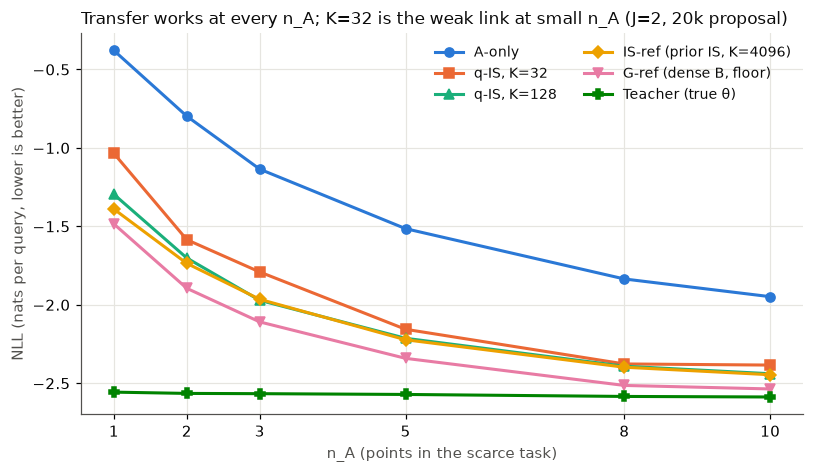

In [ ]:
w = wide(nll, 2).groupby("n_a").mean()
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ser = [("a_only", "A-only", C[0], "o"), ("qis32", "q-IS, K=32", C[1], "s"), ("qis128", "q-IS, K=128", C[2], "^"),
       ("isref", "IS-ref (prior IS, K=4096)", C[3], "D"), ("grid", "G-ref (dense B, floor)", C[4], "v"),
       ("teacher", "Teacher (true θ)", C[5], "P")]  # fmt: skip
for m, l, c, k in ser:
    ax.plot(NS, w[m], color=c, marker=k, label=l)
ax.set(xlabel="n_A (points in the scarce task)", ylabel="NLL (nats per query, lower is better)", xticks=NS)
ax.set_title("Transfer works at every n_A; K=32 is the weak link at small n_A (J=2, 20k proposal)", loc="left", fontsize=11)
ax.legend(ncol=2, fontsize=9)
fig.tight_layout()
plt.show()

## Post hoc: why the stages failed

Not pre-registered; added after seeing the table above, on the user's standing instruction to investigate failures. Sweeps: `pilot_20261102-165535`
(diagnostics, 20k proposals), `-165541` (60k proposals for J = 2, 16), `-183335` (their V0–V5 evaluation), `-183338` (their diagnostics).

### 1. Error decomposition

Uses the spec's §7 terms, with IS-ref split further by exact-posterior draws through the decoder at K = 128 (a slight upper bound on the decoder term, since K is finite).

,decoder predictive + finite B,decoder evidence,proposal + finite K (K=32),total
n_a,,,,
1,0.071,0.024,0.327,0.422
2,0.084,0.075,0.125,0.284
3,0.076,0.068,0.096,0.240
5,0.075,0.044,0.019,0.137
8,0.086,0.031,0.012,0.128
10,0.085,0.006,0.055,0.145


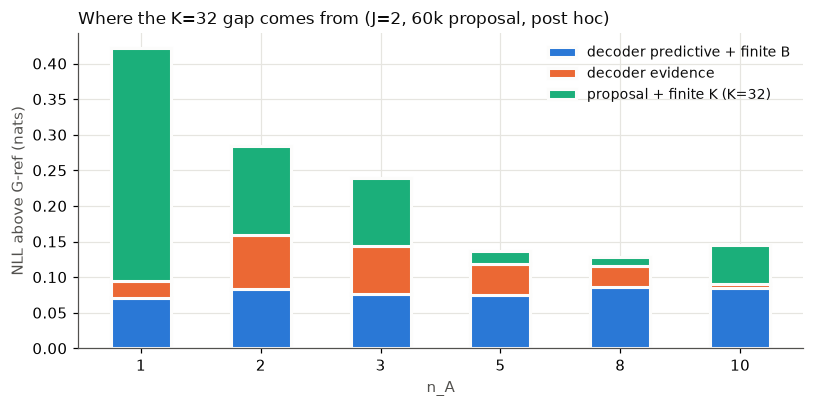

In [ ]:
w = wide(nll6, 2)
dp = pf6[(pf6.J == 2) & (pf6.metric == "nll_dec_post128")].set_index(["n_a", "task"]).value
g = w.grid
dec = (dp - g).groupby("n_a").mean()
ev = (w.isref - dp).groupby("n_a").mean()
kq = (w.qis32 - w.isref).groupby("n_a").mean()
dec_t = pd.DataFrame({"decoder predictive + finite B": dec, "decoder evidence": ev, "proposal + finite K (K=32)": kq})
dec_t["total"] = dec_t.sum(axis=1)
display(dec_t.round(3))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
x, bot = np.arange(len(NS)), np.zeros(len(NS))
for i, col in enumerate(dec_t.columns[:3]):
    v = dec_t[col].values
    ax.bar(x, v, width=.5, bottom=bot, color=C[i], label=col, edgecolor="#fcfcfb", linewidth=2)
    bot += np.clip(v, 0, None)
ax.set(xticks=x, xticklabels=NS, xlabel="n_A", ylabel="NLL above G-ref (nats)")
ax.set_title("Where the K=32 gap comes from (J=2, 60k proposal, post hoc)", loc="left", fontsize=11)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

### 2. Finite K, with and without a perfect proposal

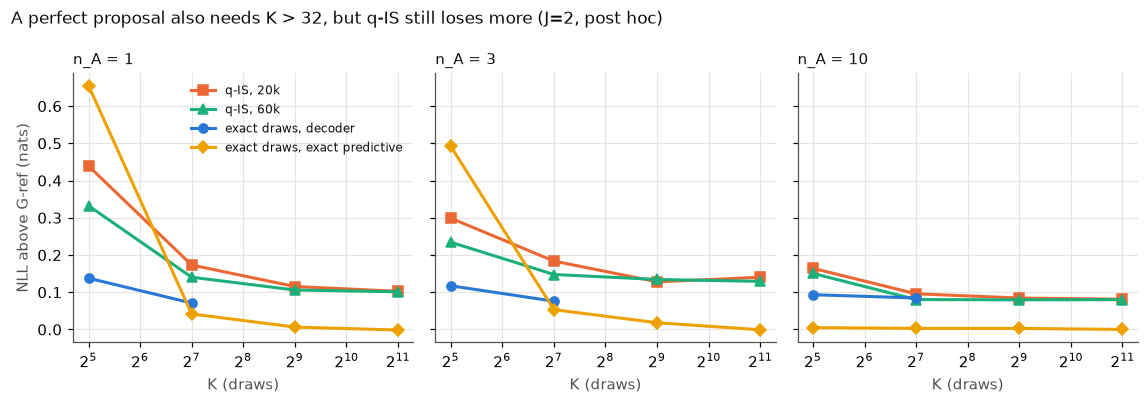

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.7), sharey=True)
gridn = mean(pf, "nll_grid")
for ax, n in zip(axs, [1, 3, 10]):
    def cur(d, pref):
        x = d[(d.J == 2) & (d.n_a == n) & d.metric.str.match(pref + r"\d+$")]
        s = x.groupby("metric").value.mean()
        s.index = [int(i.replace(pref, "")) for i in s.index]
        return s.sort_index() - gridn[n]
    for s, l, c, k in [(cur(pf, "nll_qis"), "q-IS, 20k", C[1], "s"), (cur(pf6, "nll_qis"), "q-IS, 60k", C[2], "^"),
                       (cur(pf, "nll_dec_post"), "exact draws, decoder", C[0], "o"),
                       (cur(pf, "nll_exact_post"), "exact draws, exact predictive", C[3], "D")]:  # fmt: skip
        s = s[s.index >= 32]
        ax.plot(s.index, s.values, color=c, marker=k, label=l)
    ax.set_xscale("log", base=2)
    ax.set_title(f"n_A = {n}", loc="left", fontsize=10)
    ax.set_xlabel("K (draws)")
axs[0].set_ylabel("NLL above G-ref (nats)")
axs[0].legend(fontsize=8)
fig.suptitle("A perfect proposal also needs K > 32, but q-IS still loses more (J=2, post hoc)", x=.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

In [ ]:
tt = {}
for J, d, lab in [(2, pf6, "J=2, 60k"), (16, pf6, "J=16, 60k"), (4, pf, "J=4, 20k"), (8, pf, "J=8, 20k")]:
    ref = mean(pf, "nll_grid") if J == 2 else (nll6 if J == 16 else nll).query("J == @J and method == 'isexact'").groupby("n_a").nll.mean()
    for K in (32, 128, 512, 2048):
        tt[(lab, K)] = (mean(d, f"nll_qis{K}", J) - ref).dropna()
gapk = pd.DataFrame(tt).T.round(3)
gapk.index.names = ["run", "K"]
display(gapk)
print("Reference: G-ref at J=2 (a dense-B floor); IS-exact otherwise. IS-exact median ESS (J=16, 60k):",
      med(diag6, "ess_isexact", 16).round(0).to_dict())

n_a                1      3      5      10
run       K                               
J=2, 60k  32    0.332  0.234  0.180  0.151
          128   0.140  0.148  0.122  0.080
          512   0.106  0.134  0.103  0.080
          2048  0.101  0.129  0.098  0.080
J=16, 60k 32    0.363  0.341  0.326  0.209
          128   0.112  0.165  0.156  0.097
          512   0.069  0.110  0.088  0.049
          2048  0.060  0.067  0.070  0.006
J=4, 20k  32    0.289  0.307  0.351  0.302
          128   0.201  0.209  0.205  0.231
          512   0.068  0.124  0.139  0.165
          2048  0.068  0.108  0.130  0.160
J=8, 20k  32    0.437  0.305  0.258  0.236
          128   0.155  0.159  0.014  0.008
          512   0.060  0.007 -0.105 -0.040
          2048  0.018 -0.030 -0.205 -0.099

Reference: G-ref at J=2 (a dense-B floor); IS-exact otherwise. IS-exact median ESS (J=16, 60k): {1: 4578.0, 2: 2142.0, 3: 1206.0, 5: 591.0, 8: 188.0, 10: 135.0}


### 3. Proposal efficiency across J and K

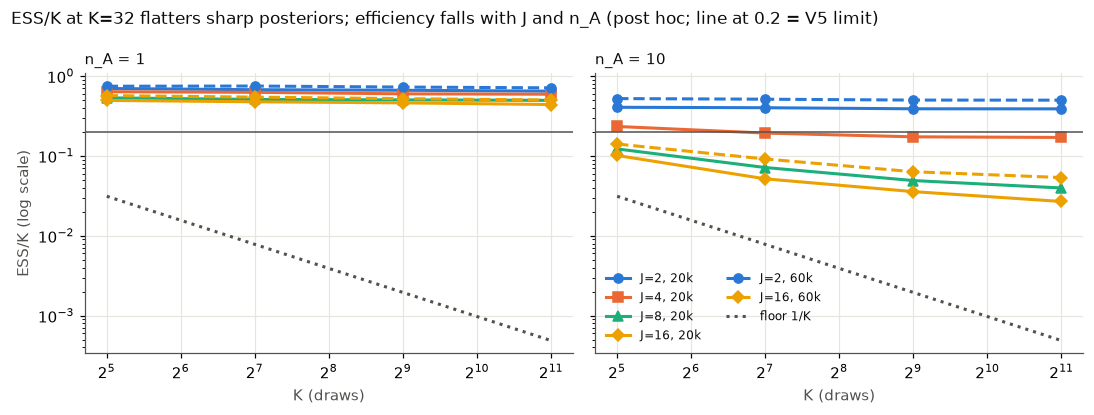

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, n in zip(axs, [1, 10]):
    for J, c, k in [(2, C[0], "o"), (4, C[1], "s"), (8, C[2], "^"), (16, C[3], "D")]:
        s = pd.Series({K: mean(pf, f"ess_qis{K}", J)[n] for K in (32, 128, 512, 2048)})
        ax.plot(s.index, s.values, color=c, marker=k, label=f"J={J}, 20k")
    for J, c, k in [(2, C[0], "o"), (16, C[3], "D")]:
        s = pd.Series({K: mean(pf6, f"ess_qis{K}", J)[n] for K in (32, 128, 512, 2048)})
        ax.plot(s.index, s.values, color=c, marker=k, ls="--", label=f"J={J}, 60k")
    ks = np.array([32, 128, 512, 2048])
    ax.plot(ks, 1 / ks, color=MUTED, ls=":", label="floor 1/K")
    ax.axhline(.2, color=MUTED, lw=1)
    ax.set_xscale("log", base=2); ax.set_yscale("log")
    ax.set_title(f"n_A = {n}", loc="left", fontsize=10)
    ax.set_xlabel("K (draws)")
axs[0].set_ylabel("ESS/K (log scale)")
axs[1].legend(fontsize=8, ncol=2)
fig.suptitle("ESS/K at K=32 flatters sharp posteriors; efficiency falls with J and n_A (post hoc; line at 0.2 = V5 limit)", x=.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

### 4. Proposal and evidence fidelity on a fine local grid

An 81² grid fitted to each task, 32 tasks. This excludes coarse-grid artefacts: the KLs do not fall, so grid resolution was not the problem.

,KL(exact||q) 20k,KL(dec||q) 20k,KL(exact||q) 60k,KL(dec||q) 60k,KL(exact||dec),"KL(exact||dec), clean B"
n_a,,,,,,
1,0.321,0.112,0.251,0.065,0.115,0.091
2,0.849,0.304,0.489,0.136,0.260,0.193
5,0.851,0.525,0.511,0.296,0.339,0.225
10,0.852,0.498,0.538,0.419,0.523,0.296


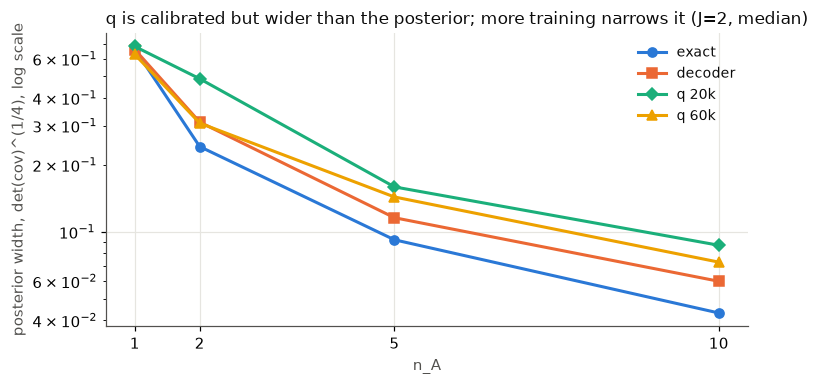

Validation NLL at n_A=5 (20k -> 60k): J=2 -0.790 -> -1.320, J=16 19.30 -> 18.56 (sweeps 151837, 165541).
ess_perm8 vs K=128 ESS, J=16, n_A=10 (20k): 0.05 0.052
ess_exact vs K=128 ESS, J=2, n_A=10 (20k): 0.274 0.401


In [ ]:
t = pd.DataFrame({f"{a} {lbl}": med(d, m) for lbl, d in [("20k", pf), ("60k", pf6)]
                  for a, m in [("KL(exact||q)", "kl_exact_q"), ("KL(dec||q)", "kl_dec_q")]})
t["KL(exact||dec)"] = med(pf6, "kl_exact_dec")
t["KL(exact||dec), clean B"] = med(pf6, "kl_exact_dec_clean")
display(t.dropna().round(3))
w = pd.DataFrame({"exact": med(pf, "w_exact"), "decoder": med(pf, "w_dec"), "q 20k": med(pf, "w_q"), "q 60k": med(pf6, "w_q")}).dropna()
fig, ax = plt.subplots(figsize=(7, 3.6))
for (col, c, k) in zip(w.columns, C, "osD^"):
    ax.plot(w.index, w[col], color=c, marker=k, label=col)
ax.set_yscale("log"); ax.set(xlabel="n_A", ylabel="posterior width, det(cov)^(1/4), log scale", xticks=[1, 2, 5, 10])
ax.set_title("q is calibrated but wider than the posterior; more training narrows it (J=2, median)", loc="left", fontsize=11)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()
print("Validation NLL at n_A=5 (20k -> 60k): J=2 -0.790 -> -1.320, J=16 19.30 -> 18.56 (sweeps 151837, 165541).")
print("ess_perm8 vs K=128 ESS, J=16, n_A=10 (20k):", round(mean(pf, "ess_perm8", 16)[10], 3), round(mean(pf, "ess_qis128", 16)[10], 3))
print("ess_exact vs K=128 ESS, J=2, n_A=10 (20k):", round(mean(pf, "ess_exact")[10], 3), round(mean(pf, "ess_qis128")[10], 3))

## Proposed verdict (not recorded; the user runs `decide`)

**Proposed: NO-GO on the pilot as pre-registered** (sweep `pilot_20261102-162127`): V1.2, V1.3, V2, V3, V4 and V5 fail. The failures do not
refute the idea. Consistency, calibration, registration and non-growing bias all held, and the largest losses shrink with more proposal
training and with K.

**Next steps, by expected value.**
1. Train the proposal to a real plateau, then measure the K needed for V4's 0.03 at n_A = 1, where the gap is still open.
2. Re-state V4/V5 at a K that a perfect proposal can meet (K ≈ 128 rather than 32), as a new pre-registration.
3. Test whether the n_A = 1 remainder is the effective K, and whether a less sharp predictive (for example marginalising a small θ jitter
   per draw) closes it. This is an idea, not a result.
4. Keep the listed V1 fallback (a small training residual) in reserve; decoder evidence costs at most 0.08 nats, so it is not the priority.